<a href="https://colab.research.google.com/github/MilagrosBrucellaria/PreEntrega14-AnalisisDistribuciones-Outliers/blob/main/PreEntrega14_AnalisisDistribuciones_Outliers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pre-entrega 14: Análisis visual de distribuciones categóricas y outliers

## Introducción
En este notebook se realiza un análisis exploratorio del dataset **Tips (Propinas)**, disponible en Seaborn. El conjunto contiene información sobre cuentas y propinas de un restaurante, combinando variables numéricas y categóricas.

### Objetivos
- Conocer la estructura y calidad general de los datos.
- Analizar variables categóricas mediante gráficos de barras.
- Calcular medidas de tendencia central y dispersión.
- Calcular e interpretar asimetría (*skewness*) y curtosis.
- Visualizar posibles valores extremos mediante boxplots y violin plots.
- Identificar y segmentar outliers con el rango intercuartílico (IQR).
- Definir una decisión fundamentada sobre su tratamiento.

### Origen de los datos
El dataset se carga desde el repositorio de datasets de **Seaborn** mediante `sns.load_dataset("tips")`. La unidad de análisis es cada cuenta registrada en el restaurante.


In [1]:
# Importación de librerías, configuración y carga del dataset
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

df_propinas = sns.load_dataset("tips")

print("Dataset cargado correctamente.")
print(f"Cantidad de filas: {df_propinas.shape[0]}")
print(f"Cantidad de columnas: {df_propinas.shape[1]}")
display(df_propinas.head())


Dataset cargado correctamente.
Cantidad de filas: 244
Cantidad de columnas: 7


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 1. Exploración, limpieza y selección de variables
Antes de analizar las distribuciones, se revisan la estructura, los tipos de datos, los valores faltantes y los registros duplicados. Los duplicados no se eliminan automáticamente porque dos mesas pueden presentar los mismos valores sin representar necesariamente un error.


In [2]:
# Revisión general y estadísticos descriptivos
print("INFORMACIÓN GENERAL")
df_propinas.info()

print("\nVALORES FALTANTES POR COLUMNA")
display(df_propinas.isna().sum().to_frame(name="valores_faltantes"))

cantidad_duplicados = df_propinas.duplicated().sum()
print(f"Cantidad de filas duplicadas: {cantidad_duplicados}")
print("Decisión: se conservan porque podrían ser observaciones reales con valores coincidentes.")

columnas_numericas = df_propinas.select_dtypes(include="number").columns.tolist()
columnas_categoricas = df_propinas.select_dtypes(exclude="number").columns.tolist()
print(f"\nVariables numéricas: {columnas_numericas}")
print(f"Variables categóricas: {columnas_categoricas}")

resumen_numerico = df_propinas[columnas_numericas].describe().T
resumen_numerico["mediana"] = df_propinas[columnas_numericas].median()
resumen_numerico["varianza"] = df_propinas[columnas_numericas].var()
resumen_numerico["rango"] = resumen_numerico["max"] - resumen_numerico["min"]

print("\nMEDIDAS DE TENDENCIA CENTRAL Y DISPERSIÓN")
display(resumen_numerico[["count", "mean", "mediana", "std", "varianza", "min", "max", "rango"]])


INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

VALORES FALTANTES POR COLUMNA


,valores_faltantes
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


Cantidad de filas duplicadas: 1
Decisión: se conservan porque podrían ser observaciones reales con valores coincidentes.

Variables numéricas: ['total_bill', 'tip', 'size']
Variables categóricas: ['sex', 'smoker', 'day', 'time']

MEDIDAS DE TENDENCIA CENTRAL Y DISPERSIÓN


,count,mean,mediana,std,varianza,min,max,rango
total_bill,244.00,19.79,17.80,8.90,79.25,3.07,50.81,47.74
tip,244.00,3.00,2.90,1.38,1.91,1.00,10.00,9.00
size,244.00,2.57,2.00,0.95,0.90,1.00,6.00,5.00


## 2. Distribución de variables categóricas
Los gráficos de barras permiten comparar la frecuencia de cada categoría. Se analizan el día, el momento del servicio, el sexo registrado y la condición de fumador.


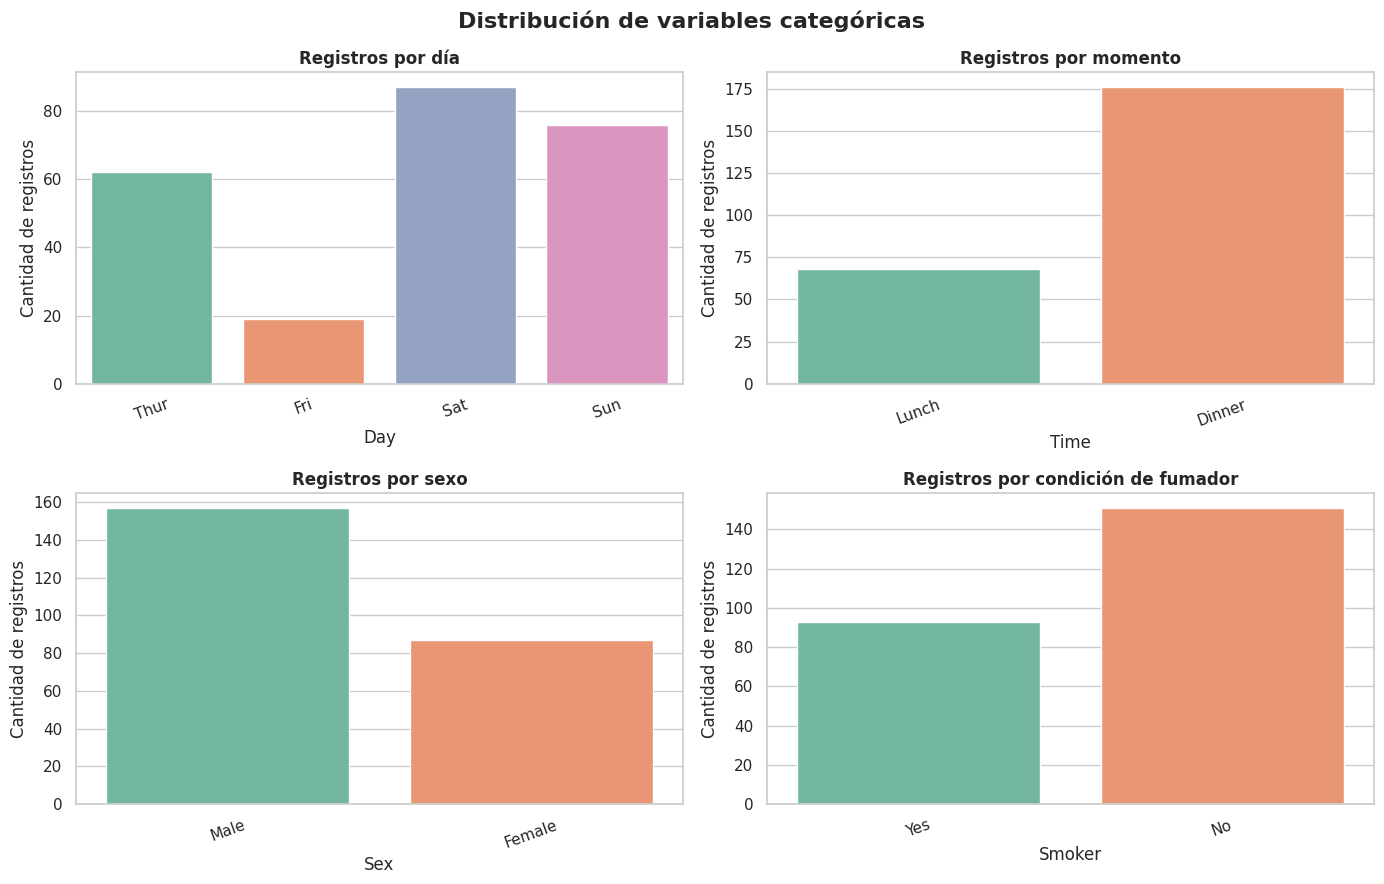

INTERPRETACIÓN
- Los gráficos permiten identificar las categorías con mayor y menor frecuencia.
- Las diferencias de tamaño deben considerarse al comparar grupos.


In [3]:
# Barplots de las principales variables categóricas
variables_categoricas_grafico = ["day", "time", "sex", "smoker"]
titulos = ["Registros por día", "Registros por momento", "Registros por sexo", "Registros por condición de fumador"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for eje, variable, titulo in zip(axes, variables_categoricas_grafico, titulos):
    frecuencias = (df_propinas[variable].value_counts(dropna=False)
                   .rename_axis(variable).reset_index(name="cantidad"))
    sns.barplot(data=frecuencias, x=variable, y="cantidad", hue=variable, legend=False, ax=eje)
    eje.set_title(titulo, fontweight="bold")
    eje.set_xlabel(variable.capitalize())
    eje.set_ylabel("Cantidad de registros")
    eje.tick_params(axis="x", rotation=20)

plt.suptitle("Distribución de variables categóricas", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

print("INTERPRETACIÓN")
print("- Los gráficos permiten identificar las categorías con mayor y menor frecuencia.")
print("- Las diferencias de tamaño deben considerarse al comparar grupos.")


## 3. Forma de las distribuciones: asimetría y curtosis
La **asimetría** indica la dirección de la cola: un valor positivo representa una cola hacia la derecha; uno negativo, hacia la izquierda; y uno cercano a cero, una distribución aproximadamente simétrica.

La **curtosis** de Pandas es el exceso respecto de una distribución normal: valores positivos sugieren colas más pesadas; valores negativos, una distribución más plana; y valores cercanos a cero, una forma similar a la normal.


In [4]:
# Cálculo e interpretación de skewness y kurtosis
forma_distribuciones = pd.DataFrame({
    "asimetria_skewness": df_propinas[columnas_numericas].skew(),
    "curtosis": df_propinas[columnas_numericas].kurtosis()
})

def interpretar_asimetria(valor):
    if valor > 0.5:
        return "Asimetría positiva: cola hacia la derecha"
    if valor < -0.5:
        return "Asimetría negativa: cola hacia la izquierda"
    return "Distribución aproximadamente simétrica"

def interpretar_curtosis(valor):
    if valor > 0.5:
        return "Curtosis positiva: colas relativamente pesadas"
    if valor < -0.5:
        return "Curtosis negativa: distribución relativamente plana"
    return "Curtosis cercana a la normal"

forma_distribuciones["interpretacion_asimetria"] = forma_distribuciones["asimetria_skewness"].apply(interpretar_asimetria)
forma_distribuciones["interpretacion_curtosis"] = forma_distribuciones["curtosis"].apply(interpretar_curtosis)
display(forma_distribuciones)

asimetria_cuenta = forma_distribuciones.loc["total_bill", "asimetria_skewness"]
curtosis_cuenta = forma_distribuciones.loc["total_bill", "curtosis"]
print("INTERPRETACIÓN DE TOTAL_BILL")
print(f"Asimetría: {asimetria_cuenta:.3f}. {interpretar_asimetria(asimetria_cuenta)}.")
print(f"Curtosis: {curtosis_cuenta:.3f}. {interpretar_curtosis(curtosis_cuenta)}.")
print("La asimetría positiva indica que la mayoría de las cuentas se concentra en valores bajos o medios y existe una cola formada por algunas cuentas elevadas.")


,asimetria_skewness,curtosis,interpretacion_asimetria,interpretacion_curtosis
total_bill,1.13,1.22,Asimetría positiva: cola hacia la derecha,Curtosis positiva: colas relativamente pesadas
tip,1.47,3.65,Asimetría positiva: cola hacia la derecha,Curtosis positiva: colas relativamente pesadas
size,1.45,1.73,Asimetría positiva: cola hacia la derecha,Curtosis positiva: colas relativamente pesadas


INTERPRETACIÓN DE TOTAL_BILL
Asimetría: 1.133. Asimetría positiva: cola hacia la derecha.
Curtosis: 1.218. Curtosis positiva: colas relativamente pesadas.
La asimetría positiva indica que la mayoría de las cuentas se concentra en valores bajos o medios y existe una cola formada por algunas cuentas elevadas.


## 4. Visualización de valores extremos
El **boxplot** resume mediana, cuartiles y posibles valores atípicos. El **violin plot** agrega la densidad de los datos. Ambos gráficos analizan `total_bill` según el día.


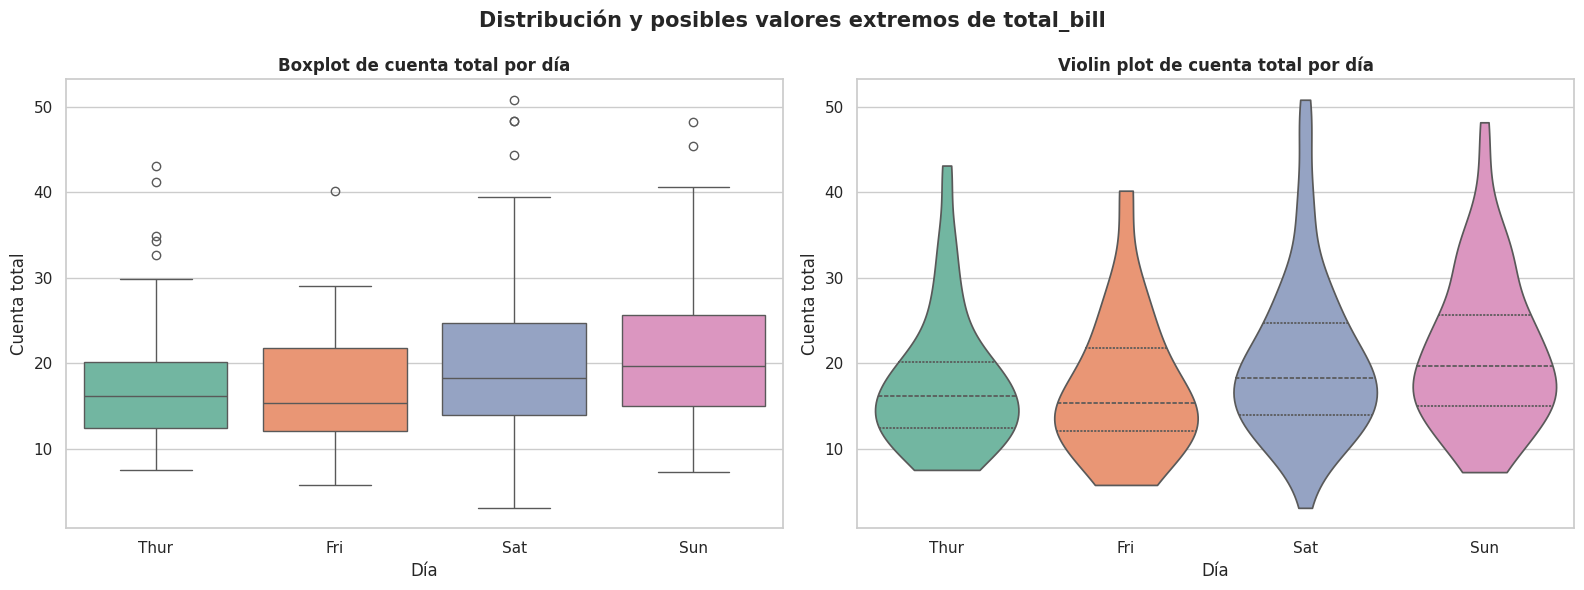

INTERPRETACIÓN VISUAL
- El boxplot muestra puntos por encima de los bigotes, compatibles con posibles outliers.
- El violin plot muestra mayor concentración en cuentas bajas y medias.
- La escasa densidad en valores altos es coherente con una cola hacia la derecha.


In [5]:
# Boxplot y violin plot de la cuenta total según el día
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df_propinas, x="day", y="total_bill", hue="day", legend=False, ax=axes[0])
axes[0].set_title("Boxplot de cuenta total por día", fontweight="bold")
axes[0].set_xlabel("Día")
axes[0].set_ylabel("Cuenta total")

sns.violinplot(data=df_propinas, x="day", y="total_bill", hue="day", legend=False,
               inner="quartile", cut=0, ax=axes[1])
axes[1].set_title("Violin plot de cuenta total por día", fontweight="bold")
axes[1].set_xlabel("Día")
axes[1].set_ylabel("Cuenta total")

plt.suptitle("Distribución y posibles valores extremos de total_bill", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

print("INTERPRETACIÓN VISUAL")
print("- El boxplot muestra puntos por encima de los bigotes, compatibles con posibles outliers.")
print("- El violin plot muestra mayor concentración en cuentas bajas y medias.")
print("- La escasa densidad en valores altos es coherente con una cola hacia la derecha.")


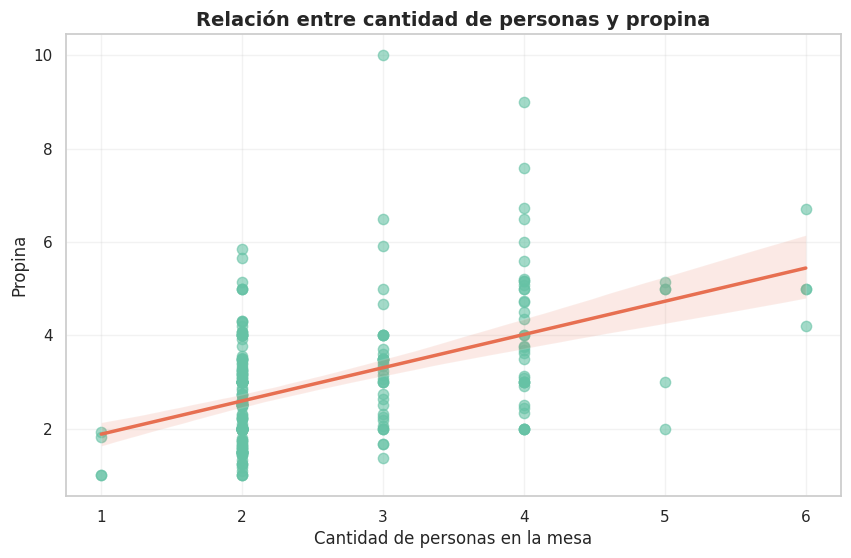

Correlación entre cantidad de personas y propina: 0.489


In [11]:
# Relación entre cantidad de personas y propina
# Diagrama de dispersión con recta de regresión

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_propinas,
    x="size",
    y="tip",
    scatter_kws={
        "alpha": 0.60,
        "s": 55,
        "color": "#66c2a5"
    },
    line_kws={
        "color": "#e76f51",
        "linewidth": 2.5
    }
)

plt.title(
    "Relación entre cantidad de personas y propina",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Cantidad de personas en la mesa")
plt.ylabel("Propina")

plt.xticks(sorted(df_propinas["size"].unique()))
plt.grid(alpha=0.25)

plt.show()

# Correlación entre tamaño de la mesa y propina

correlacion_size_tip = df_propinas["size"].corr(df_propinas["tip"])

print(
    f"Correlación entre cantidad de personas y propina: "
    f"{correlacion_size_tip:.3f}"
)

### Interpretación de la relación entre cantidad de personas y propina

El gráfico muestra una **tendencia positiva entre la cantidad de personas y la propina**: a medida que aumenta el tamaño de la mesa, la propina total tiende a ser mayor.

La correlación obtenida es de **0,489**, lo que indica una **relación positiva moderada**. Sin embargo, los puntos presentan una dispersión importante alrededor de la recta, por lo que la cantidad de personas no explica por sí sola el importe de la propina.

También se observan algunos valores alejados de la tendencia general, especialmente en mesas de 3 y 4 personas. Estos puntos no necesariamente son errores ni outliers según IQR, sino registros cuyo comportamiento se diferencia del esperado según la tendencia.

Por lo tanto, puede afirmarse que existe una asociación entre ambas variables, pero **no una relación causal ni suficientemente fuerte como para explicar la propina únicamente a partir del tamaño de la mesa**.

## 6. Detección y segmentación de outliers mediante IQR
El rango intercuartílico se calcula como `IQR = Q3 - Q1`. Los límites son `Q1 - 1.5 × IQR` y `Q3 + 1.5 × IQR`. Los registros fuera de esos límites se segmentan como outliers. La técnica se aplica a `total_bill`.


In [6]:
# Aplicación documentada del método IQR sobre total_bill
variable_outliers = "total_bill"
q1 = df_propinas[variable_outliers].quantile(0.25)
q3 = df_propinas[variable_outliers].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Segmentación sin modificar el dataset original
df_segmentado = df_propinas.copy()
condicion_outlier = ((df_segmentado[variable_outliers] < limite_inferior) |
                     (df_segmentado[variable_outliers] > limite_superior))
df_segmentado["segmento_iqr"] = "Registro habitual"
df_segmentado.loc[condicion_outlier, "segmento_iqr"] = "Outlier"

outliers_total_bill = df_segmentado[df_segmentado["segmento_iqr"] == "Outlier"].copy()
porcentaje_outliers = len(outliers_total_bill) / len(df_segmentado) * 100

print("RESULTADOS DEL MÉTODO IQR")
print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Límite inferior: {limite_inferior:.2f}")
print(f"Límite superior: {limite_superior:.2f}")
print(f"Cantidad de outliers: {len(outliers_total_bill)}")
print(f"Porcentaje de outliers: {porcentaje_outliers:.2f}%")

print("\nREGISTROS IDENTIFICADOS COMO OUTLIERS")
display(outliers_total_bill.sort_values(variable_outliers, ascending=False))

print("\nCOMPARACIÓN DE SEGMENTOS")
resumen_segmentos = (df_segmentado.groupby("segmento_iqr", observed=True)[variable_outliers]
                     .agg(cantidad="count", promedio="mean", mediana="median", minimo="min", maximo="max"))
display(resumen_segmentos)


RESULTADOS DEL MÉTODO IQR
Q1: 13.35
Q3: 24.13
IQR: 10.78
Límite inferior: -2.82
Límite superior: 40.30
Cantidad de outliers: 9
Porcentaje de outliers: 3.69%

REGISTROS IDENTIFICADOS COMO OUTLIERS


,total_bill,tip,sex,smoker,day,time,size,segmento_iqr
170,50.81,10.00,Male,Yes,Sat,Dinner,3,Outlier
212,48.33,9.00,Male,No,Sat,Dinner,4,Outlier
59,48.27,6.73,Male,No,Sat,Dinner,4,Outlier
156,48.17,5.00,Male,No,Sun,Dinner,6,Outlier
182,45.35,3.50,Male,Yes,Sun,Dinner,3,Outlier
102,44.30,2.50,Female,Yes,Sat,Dinner,3,Outlier
197,43.11,5.00,Female,Yes,Thur,Lunch,4,Outlier
142,41.19,5.00,Male,No,Thur,Lunch,5,Outlier
184,40.55,3.00,Male,Yes,Sun,Dinner,2,Outlier



COMPARACIÓN DE SEGMENTOS


,cantidad,promedio,mediana,minimo,maximo
segmento_iqr,,,,,
Outlier,9,45.56,45.35,40.55,50.81
Registro habitual,235,18.80,17.46,3.07,40.17


## Conclusión final

El análisis permitió caracterizar las principales distribuciones del dataset **Tips** utilizando medidas estadísticas y diferentes herramientas de visualización.

Las variables numéricas presentan **asimetría positiva**, lo que indica una mayor concentración de observaciones en valores bajos e intermedios y una cola hacia valores elevados. En `total_bill`, esta característica se refleja en una media de **19,79**, superior a la mediana de **17,80**, y en un skewness de **1,13**.

Los gráficos también resultaron consistentes con estos resultados. El **Boxplot** permitió visualizar posibles valores extremos, mientras que el **Violin Plot** mostró cómo se concentra la distribución y cómo disminuye su densidad hacia los importes más elevados.

La aplicación del método **IQR** sobre `total_bill` estableció un límite superior de **40,30** e identificó **9 outliers**, equivalentes al **3,69 % del dataset**. Los registros habituales presentan un promedio de **18,80**, mientras que los valores identificados como atípicos alcanzan un promedio de **45,56**.

Como análisis complementario, se estudió la relación entre la **cantidad de personas y la propina**. El gráfico de dispersión y la recta de tendencia muestran una relación creciente, respaldada por una correlación de **0,489**. Esto representa una **asociación positiva moderada**: las mesas de mayor tamaño tienden a registrar propinas totales más altas, aunque existe suficiente dispersión como para concluir que intervienen también otros factores.

En conjunto, existe una **coherencia entre los estadísticos descriptivos, la asimetría, las visualizaciones y la detección mediante IQR**. Esto demuestra la utilidad de combinar distintas técnicas para comprender mejor el comportamiento de los datos en lugar de analizar cada resultado de forma aislada.

Finalmente, se decidió **conservar los outliers**, ya que un valor estadísticamente atípico no necesariamente representa un dato incorrecto. Antes de eliminar o transformar estos registros sería necesario analizar su contexto y verificar si corresponden a valores reales o a errores de carga.

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib
import sys

print(f"Python: {sys.version.split()[0]}")
print(f"pandas: {pd.__version__}")
print(f"seaborn: {sns.__version__}")
print(f"matplotlib: {matplotlib.__version__}")

Python: 3.13.18
pandas: 2.2.3
seaborn: 0.13.2
matplotlib: 3.10.0
